# Modularity on the Karate Club Graph
**DSC212 — Graph Theory Module**

Implement recursive spectral bisection using the global modularity matrix, then track how node-level network metrics change as inter-community edges are removed.

**Reference:** Newman, M. E. J. (2006). “Modularity and community structure in networks.” *Proceedings of the National Academy of Sciences*, **103**(23), 8577–8582.

## Setup: graph and global modularity matrix

The Zachary Karate Club graph has 34 nodes and 78 edges. We construct its adjacency matrix and degree vector once, then compute the global modularity matrix $B = A - \frac{\mathbf{k}\mathbf{k}^{\top}}{2m}$. Every recursive community matrix is sliced directly from this fixed matrix.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

G = nx.karate_club_graph()
nodes = list(G.nodes())
node_index = {node: i for i, node in enumerate(nodes)}

A = nx.to_numpy_array(G, nodelist=nodes, dtype=float)
k = A.sum(axis=1)
m = G.number_of_edges()
B = A - np.outer(k, k) / (2 * m)

print(f"Nodes: {G.number_of_nodes()} | Edges: {m}")
print(f"Global B shape: {B.shape} | Symmetry error: {np.max(np.abs(B - B.T)):.2e}")

Nodes: 34 | Edges: 78
Global B shape: (34, 34) | Symmetry error: 0.00e+00


## 1. Recursive spectral modularity

Each active community \(C\) is tested using `B[np.ix_(indices, indices)]`, a principal submatrix of the **global** \(B\). We split by the leading eigenvector's signs only when its largest eigenvalue exceeds $(10^{-10})$ and both sign groups are nonempty; rounds process all currently active communities, and each successful round is logged.

In [2]:
def recursive_spectral_bisection(B, nodes, m, threshold=1e-10):
    """Breadth-wise recursive bisection using slices of the global B matrix."""
    node_index = {node: i for i, node in enumerate(nodes)}
    partition = [list(nodes)]
    partition_history = {0: [list(nodes)]}
    split_log = {}
    terminal_checks = []
    frontier = [list(nodes)]
    iteration = 0

    while frontier:
        frontier_keys = {tuple(C) for C in frontier}
        updated_partition = []
        next_frontier = []
        round_splits = []

        for C in partition:
            if tuple(C) not in frontier_keys:
                updated_partition.append(C)
                continue

            idx = [node_index[node] for node in C]
            B_C = B[np.ix_(idx, idx)]  # direct restriction of the one global B
            eigenvalues, eigenvectors = np.linalg.eigh(B_C)
            leading_value = float(eigenvalues[-1])
            leading_vector = eigenvectors[:, -1]

            positive = [node for node, value in zip(C, leading_vector) if value > 0]
            nonpositive = [node for node, value in zip(C, leading_vector) if value <= 0]

            if leading_value <= threshold:
                terminal_checks.append((iteration + 1, tuple(C), leading_value,
                                        "largest eigenvalue is not above threshold"))
                updated_partition.append(C)
            elif not positive or not nonpositive:
                terminal_checks.append((iteration + 1, tuple(C), leading_value,
                                        "sign rule gives an empty side"))
                updated_partition.append(C)
            else:
                updated_partition.extend([positive, nonpositive])
                next_frontier.extend([positive, nonpositive])
                round_splits.append({
                    "parent": list(C),
                    "positive": positive,
                    "nonpositive": nonpositive,
                    "lambda_max": leading_value
                })

        if not round_splits:
            break

        iteration += 1
        partition = updated_partition
        partition_history[iteration] = [list(C) for C in partition]
        split_log[iteration] = round_splits
        frontier = next_frontier

    return partition_history, split_log, terminal_checks


partition_history, split_log, terminal_checks = recursive_spectral_bisection(
    B, nodes, m, threshold=1e-10
)

print(f"Successful split rounds: {len(split_log)}")
print(f"Final communities: {len(partition_history[max(partition_history)])}\n")

for iteration, partition in partition_history.items():
    label = "Initial partition" if iteration == 0 else f"After round {iteration}"
    groups = " | ".join(
        f"C{j + 1}={sorted(C)}" for j, C in enumerate(partition)
    )
    print(f"{label} ({len(partition)} communities): {groups}")

print("\nSuccessful splits by round:")
for iteration, records in split_log.items():
    details = ", ".join(
        f"|C|={len(r['parent'])} → {len(r['positive'])}+{len(r['nonpositive'])}, "
        f"λmax={r['lambda_max']:.4f}"
        for r in records
    )
    print(f"Round {iteration}: {details}")

print(f"\nTerminal candidate checks: {len(terminal_checks)}")
nonpositive_stops = [check for check in terminal_checks
                     if check[3] == "largest eigenvalue is not above threshold"]
one_sided_stops = [check for check in terminal_checks
                   if check[3] == "sign rule gives an empty side"]
print(f"Stopped by eigenvalue threshold: {len(nonpositive_stops)}")
print(f"Positive-eigenvalue candidates with a one-sided sign vector: {len(one_sided_stops)}")
for round_number, community, leading_value, reason in one_sided_stops:
    print(f"  round {round_number}, C={list(community)}, "
          f"lambda_max={leading_value:.6f}: retained (empty side avoided)")

Successful split rounds: 6
Final communities: 13

Initial partition (1 communities): C1=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
After round 1 (2 communities): C1=[8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33] | C2=[0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
After round 2 (4 communities): C1=[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33] | C2=[23, 24, 25, 27, 28, 31] | C3=[1, 2, 3, 7, 12, 13, 19, 21] | C4=[0, 4, 5, 6, 10, 11, 16, 17]
After round 3 (8 communities): C1=[26, 29] | C2=[8, 9, 14, 15, 18, 20, 22, 30, 32, 33] | C3=[24, 25, 28, 31] | C4=[23, 27] | C5=[1, 2, 19, 21] | C6=[3, 7, 12, 13] | C7=[0, 11, 17] | C8=[4, 5, 6, 10, 16]
After round 4 (11 communities): C1=[26, 29] | C2=[9, 14, 15, 18, 20, 22, 32, 33] | C3=[8, 30] | C4=[24, 25, 28, 31] | C5=[23, 27] | C6=[2] | C7=[1, 19, 21] | C8=[3, 7, 12] | C9=[13] | C10=[0, 11, 17] | C11=[4, 5, 6, 10, 16]
After round 

## 1. Community split visualizations

A single spring layout (seed 42) is reused in every panel so node positions remain comparable. Each panel shows the graph after one successful split round: edges joining different communities are removed, communities receive distinct colors, and every node is labeled by ID.

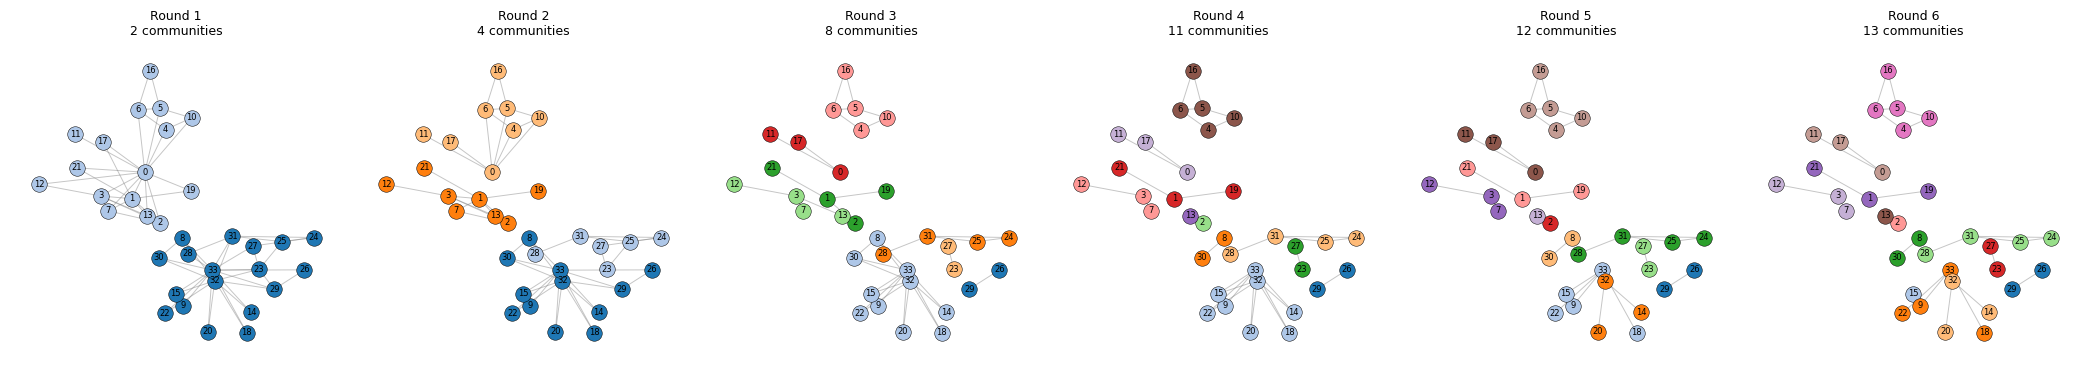

In [3]:
def prune_intercommunity_edges(graph, partition):
    community_of = {
        node: community_id
        for community_id, community in enumerate(partition)
        for node in community
    }
    pruned = graph.copy()
    cut_edges = [(u, v) for u, v in graph.edges()
                 if community_of[u] != community_of[v]]
    pruned.remove_edges_from(cut_edges)
    return pruned


layout = nx.spring_layout(G, seed=42)
plot_iterations = list(partition_history.keys())[1:]
palette = plt.get_cmap("tab20")

fig, axes = plt.subplots(1, len(plot_iterations),
                         figsize=(3.5 * len(plot_iterations), 3.8))
if len(plot_iterations) == 1:
    axes = [axes]

for ax, iteration in zip(axes, plot_iterations):
    partition = partition_history[iteration]
    H = prune_intercommunity_edges(G, partition)
    nx.draw_networkx_edges(H, layout, ax=ax, width=0.7, alpha=0.45,
                           edge_color="gray")
    for community_id, community in enumerate(partition):
        nx.draw_networkx_nodes(
            H, layout, nodelist=community, ax=ax,
            node_color=[palette(community_id % 20)],
            node_size=125, linewidths=0.35, edgecolors="black"
        )
    nx.draw_networkx_labels(H, layout, ax=ax, font_size=6)
    ax.set_title(f"Round {iteration}\n{len(partition)} communities", fontsize=9)
    ax.set_axis_off()

fig.tight_layout()
plt.show()

## 3. Node metrics and their evolution

For each stored partition, we remove edges between communities while retaining all 34 nodes, then calculate NetworkX degree, betweenness, closeness, and clustering values. Iteration 0 is included as the unpruned baseline; the plots show every node, with nodes ranking in the top four at either endpoint highlighted and labeled.

In [4]:
metric_history = {
    "degree_centrality": {},
    "betweenness_centrality": {},
    "closeness_centrality": {},
    "clustering": {}
}
graph_history = {}

for iteration, partition in partition_history.items():
    H = prune_intercommunity_edges(G, partition)
    graph_history[iteration] = H
    metric_history["degree_centrality"][iteration] = nx.degree_centrality(H)
    metric_history["betweenness_centrality"][iteration] = nx.betweenness_centrality(H)
    metric_history["closeness_centrality"][iteration] = nx.closeness_centrality(H)
    metric_history["clustering"][iteration] = nx.clustering(H)

print("Metric snapshots (iteration keys):", list(metric_history["degree_centrality"].keys()))
print("All snapshots retain all nodes:",
      all(set(H.nodes()) == set(nodes) for H in graph_history.values()))
print("Final graph: ", graph_history[max(graph_history)].number_of_edges(),
      "within-community edges remain")

Metric snapshots (iteration keys): [0, 1, 2, 3, 4, 5, 6]
All snapshots retain all nodes: True
Final graph:  24 within-community edges remain


The four panels compare all 34 node trajectories over the same split rounds. Faint lines represent the remaining nodes, while highlighted lines and legends identify nodes ranked among the four highest at the initial or final snapshot for that metric.

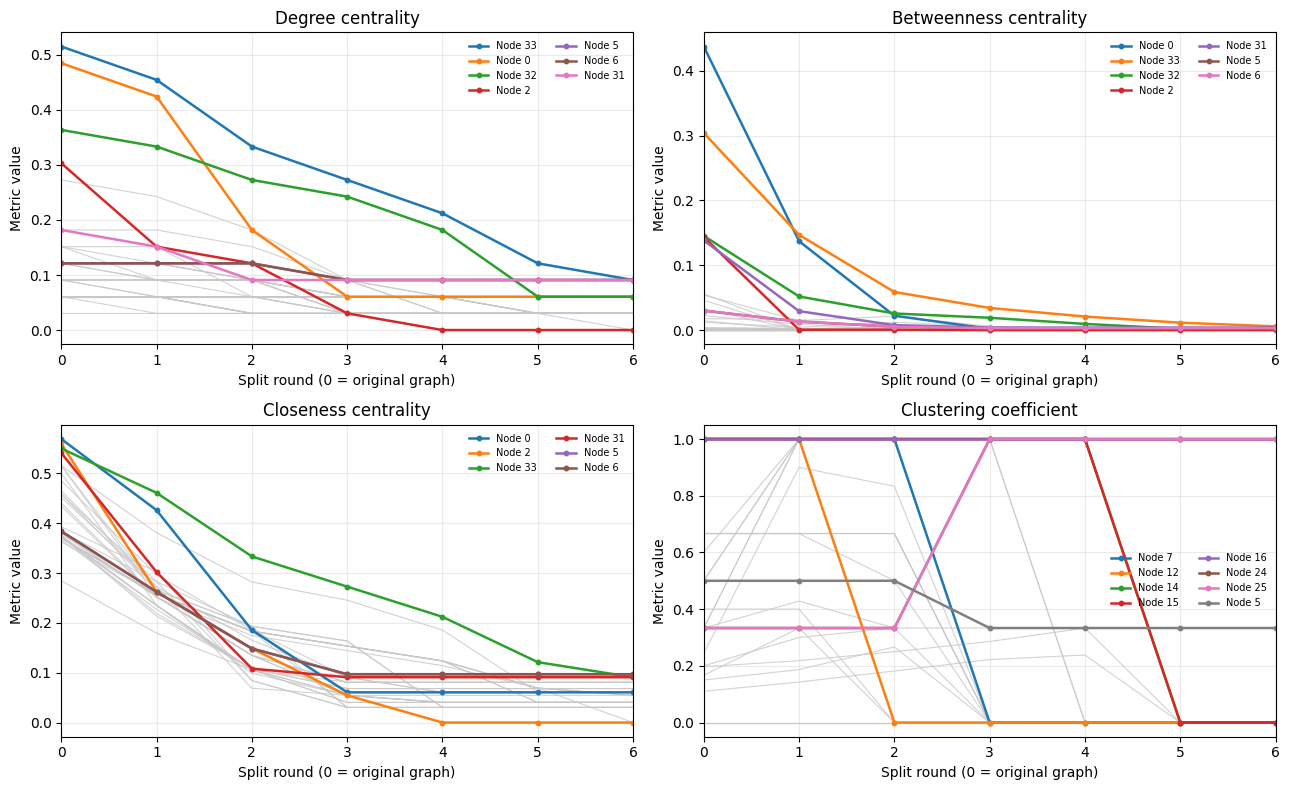

In [5]:
metric_titles = {
    "degree_centrality": "Degree centrality",
    "betweenness_centrality": "Betweenness centrality",
    "closeness_centrality": "Closeness centrality",
    "clustering": "Clustering coefficient"
}
iterations = list(partition_history.keys())

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes = axes.ravel()
key_colors = plt.get_cmap("tab10")

for ax, metric_name in zip(axes, metric_titles):
    values_by_iteration = metric_history[metric_name]
    first_values = values_by_iteration[iterations[0]]
    last_values = values_by_iteration[iterations[-1]]
    top_first = sorted(nodes, key=lambda node: (-first_values[node], node))[:4]
    top_last = sorted(nodes, key=lambda node: (-last_values[node], node))[:4]
    key_nodes = list(dict.fromkeys(top_first + top_last))

    for node in nodes:
        if node in key_nodes:
            continue
        y = [values_by_iteration[i][node] for i in iterations]
        ax.plot(iterations, y, color="0.78", linewidth=0.8, alpha=0.8)

    for j, node in enumerate(key_nodes):
        y = [values_by_iteration[i][node] for i in iterations]
        color = key_colors(j % 10)
        ax.plot(iterations, y, marker="o", markersize=3.2,
                linewidth=1.8, color=color, label=f"Node {node}")
    ax.set_title(metric_titles[metric_name])
    ax.set_xlabel("Split round (0 = original graph)")
    ax.set_ylabel("Metric value")
    ax.set_xticks(iterations)
    ax.set_xlim(iterations[0], iterations[-1])
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=7, ncol=2, frameon=False, loc="best")

fig.tight_layout()
plt.show()

## Discussion

- **Persistent hubs and bridges:** Node **33** is the most persistent high-centrality node: it leads degree centrality after the first split and remains the leading betweenness node from round 1 onward. Node **32** is also prominent in the early degree, betweenness, and closeness rankings. Node **0** is especially important in the original graph, but its global centrality drops sharply after the first fragmentation.
- **Degree centrality:** It generally falls as inter-community edges are deleted because nodes lose direct neighbors while the normalization remains based on all 34 nodes. For example, node 33 drops from about **0.515** initially to about **0.091** in the final pruned graph.
- **Betweenness centrality:** It falls sharply as cross-community bridges disappear; shortest paths become confined to smaller components. Node 0 falls from about **0.438** initially to about **0.0019** in the final graph.
- **Closeness centrality:** It generally decreases as the graph fragments, since nodes cannot reach vertices in other components. NetworkX's default disconnected-graph correction is used.
- **Clustering coefficient:** It is local rather than global, so it is not necessarily monotonic. It can remain high or increase when a node's retained neighbors form a tight group, but it can decrease when removed edges break triangles.

**Sign-splitting edge case:** Ten tested communities had $\left(\lambda_{\max} > 10^{-10}\right)$, but their leading eigenvectors contained entries of only one sign.